<a href="https://colab.research.google.com/github/ashkhenmazmanyan/DevContainer/blob/master/PINN_for_the_Silverbox_oscillator.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
import numpy as np
import scipy.io

mat_filename = "SNLS80mV.mat"

if not os.path.exists(mat_filename):
    raise FileNotFoundError("SNLS80mV.mat ֆայլը չկա Colab-ում։")

# 1. Կարդում ենք .mat ֆայլը scipy.io-ով
data = scipy.io.loadmat(mat_filename)

# V1 -> u (մուտք), V2 -> y (ելք)
u_raw = data['V1'].squeeze()
y_raw = data['V2'].squeeze()

# 2. Վերցնում ենք [42650 : 46746] հատվածը (4096 կետ)
start_idx = 42650
end_idx = 46746

u_excerpt = u_raw[start_idx:end_idx]
y_excerpt = y_raw[start_idx:end_idx]

# 3. Հանում ենք միջին արժեքները (Centering)
u_centered = u_excerpt - np.mean(u_excerpt)
y_centered = y_excerpt - np.mean(y_excerpt)

# 4. Բաժանում ենք Train (3072) և Test (1024)
u_train, y_train = u_centered[:3072], y_centered[:3072]
u_test, y_test = u_centered[3072:], y_centered[3072:]

# Ժամանակային քայլ
fs = 610.35
dt = 1.0 / fs


print("--- Տվյալների ամփոփում ---")
print(f"Ամբողջ հատվածի չափսը: {len(u_centered)} կետ")
print(f"Train չափսը: {len(u_train)} կետ ({len(u_train)*dt:.2f} վրկ)")
print(f"Test չափսը:  {len(u_test)} կետ ({len(u_test)*dt:.2f} վրկ)")
print(f"dt (ժամանակային քայլ): {dt:.6f} վրկ")

--- Տվյալների ամփոփում ---
Ամբողջ հատվածի չափսը: 4096 կետ
Train չափսը: 3072 կետ (5.03 վրկ)
Test չափսը:  1024 կետ (1.68 վրկ)
dt (ժամանակային քայլ): 0.001638 վրկ


In [2]:
import torch
import torch.nn as nn

# 1. Նեյրոնային ցանց (MLP) արագացման (acceleration) հաշվարկման համար
class AccelerationNet(nn.Module):
    def __init__(self, hidden_dim=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(3, hidden_dim),   # Մուտքը՝ (y, v, u) -> 3 չափանի
            nn.Tanh(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, 1)    # Ելքը՝ a = d2y/dt2 -> 1 չափանի
        )

    def forward(self, y, v, u):
        # Կապակցում ենք (y, v, u) վեկտորները մեկ tensor-ի մեջ
        x = torch.cat([y, v, u], dim=-1)
        return self.net(x)

# 2. Runge-Kutta 4th Order (RK4) ինտեգրման մեկ քայլ
def rk4_step(model, y, v, u, dt):
    """
    y, v, u - ընթացիկ վիճակներ (PyTorch Tensors)
    dt - ժամանակային քայլ (1 / fs)
    """
    # System dynamics: dy/dt = v, dv/dt = alpha(y, v, u)

    # k1
    k1_y = v
    k1_v = model(y, v, u)

    # k2
    y_k2 = y + 0.5 * dt * k1_y
    v_k2 = v + 0.5 * dt * k1_v
    k2_y = v_k2
    k2_v = model(y_k2, v_k2, u)

    # k3
    y_k3 = y + 0.5 * dt * k2_y
    v_k3 = v + 0.5 * dt * k2_v
    k3_y = v_k3
    k3_v = model(y_k3, v_k3, u)

    # k4
    y_k4 = y + dt * k3_y
    v_k4 = v + dt * k3_v
    k4_y = v_k4
    k4_v = model(y_k4, v_k4, u)

    # Նոր վիճակի հաշվարկ
    y_next = y + (dt / 6.0) * (k1_y + 2.0 * k2_y + 2.0 * k3_y + k4_y)
    v_next = v + (dt / 6.0) * (k1_v + 2.0 * k2_v + 2.0 * k3_v + k4_v)

    return y_next, v_next

print("--- Մոդելը և RK4 ինտեգրատորը հաջողությամբ ստեղծվեցին ---")

--- Մոդելը և RK4 ինտեգրատորը հաջողությամբ ստեղծվեցին ---


In [3]:
import torch.optim as optim

# 1. Տվյալները ձևափոխում ենք PyTorch Tensor-ների
u_train_t = torch.tensor(u_train, dtype=torch.float32).unsqueeze(-1)
y_train_t = torch.tensor(y_train, dtype=torch.float32).unsqueeze(-1)
dt_tensor = torch.tensor(dt, dtype=torch.float32)

# 2. Սկզբնական արագության (velocity) հաշվարկ
v_train_fd = np.gradient(y_train, dt)
v_train_t = torch.tensor(v_train_fd, dtype=torch.float32).unsqueeze(-1)

# 3. Մոդելի և օպտիմիզատորի ստեղծում
model = AccelerationNet(hidden_dim=64)
optimizer = optim.Adam(model.parameters(), lr=3e-3)
criterion = torch.nn.MSELoss()

rollout_len = 32   # Rollout պատուհանի երկարությունը
num_steps = 1500   # Ուսուցման քայլերի քանակը
batch_size = 32    # Batch չափսը

print("--- Ուսուցման մեկնարկ ---")

for step in range(1, num_steps + 1):
    optimizer.zero_grad()

    # Ընտրում ենք 32 պատահական սկզբնակետեր միանգամից
    max_idx = len(u_train) - rollout_len - 1
    start_indices = np.random.randint(0, max_idx, size=batch_size)

    # Վերցնում ենք բոլոր 32 նմուշների սկզբնական վիճակները (shape: [32, 1])
    y_curr = y_train_t[start_indices]
    v_curr = v_train_t[start_indices]

    loss = 0.0
    for t in range(rollout_len):
        u_curr = u_train_t[start_indices + t]
        y_target = y_train_t[start_indices + t + 1]

        # RK4 քայլը կատարվում է 32 նմուշի համար զուգահեռ
        y_next, v_next = rk4_step(model, y_curr, v_curr, u_curr, dt_tensor)
        loss += criterion(y_next, y_target)

        y_curr, v_curr = y_next, v_next

    loss = loss / rollout_len
    loss.backward()
    optimizer.step()

    if step % 300 == 0 or step == 1:
        print(f"Step {step:4d}/{num_steps} | Loss (MSE): {loss.item():.8f}")

print("--- Ուսուցումն ավարտվեց ---")

--- Ուսուցման մեկնարկ ---
Step    1/1500 | Loss (MSE): 0.39992926
Step  300/1500 | Loss (MSE): 0.33368951
Step  600/1500 | Loss (MSE): 0.32500029
Step  900/1500 | Loss (MSE): 0.25205192
Step 1200/1500 | Loss (MSE): 0.21106318
Step 1500/1500 | Loss (MSE): 0.34601751
--- Ուսուցումն ավարտվեց ---


--- Free-Run Evaluation Արդյունքներ ---
Train RMSE (3072 կետ): 0.113606 V
Test RMSE  (1024 կետ): 0.060501 V
Test RMSE-ն դեռ 0.06 V-ից մեծ է, կարելի է ուսուցման քայլերն ավելացնել։


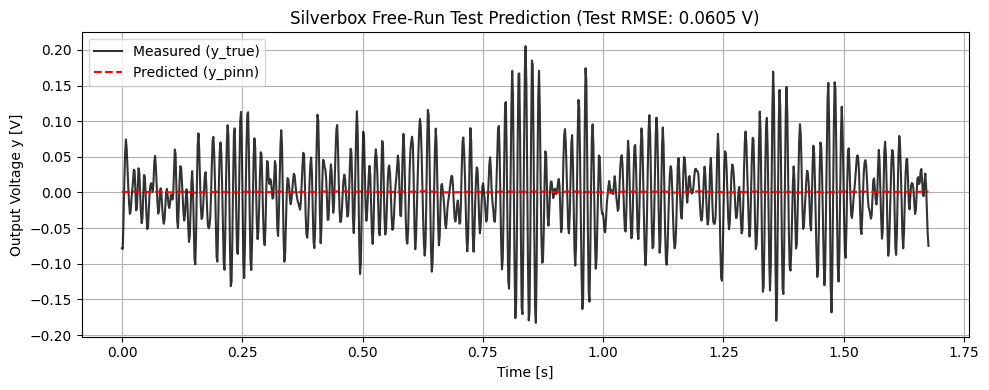

In [4]:
import matplotlib.pyplot as plt

# 1. Պատրաստում ենք ամբողջական տվյալների tensor-ները (4096 կետ)
u_all_t = torch.tensor(u_centered, dtype=torch.float32).unsqueeze(-1)
y_all_t = torch.tensor(y_centered, dtype=torch.float32).unsqueeze(-1)

# 2. Free-run ինտեգրում առաջին կետից սկսած
y_pred_list = []

# Սկզբնական վիճակ (t=0)
y_curr = y_all_t[0:1]
v_curr = torch.tensor([[v_train_fd[0]]], dtype=torch.float32)

model.eval()
with torch.no_grad():
    for t in range(len(u_centered)):
        y_pred_list.append(y_curr.item())
        if t < len(u_centered) - 1:
            u_curr = u_all_t[t:t+1]
            y_next, v_next = rk4_step(model, y_curr, v_curr, u_curr, dt_tensor)
            y_curr, v_curr = y_next, v_next

y_pred = np.array(y_pred_list)

# 3. Հաշվում ենք Free-run RMSE-ները Train և Test հատվածների համար
train_rmse = np.sqrt(np.mean((y_pred[:3072] - y_train)**2))
test_rmse = np.sqrt(np.mean((y_pred[3072:] - y_test)**2))

print("--- Free-Run Evaluation Արդյունքներ ---")
print(f"Train RMSE (3072 կետ): {train_rmse:.6f} V")
print(f"Test RMSE  (1024 կետ): {test_rmse:.6f} V")

if test_rmse < 0.06:
    print("Test RMSE-ն փոքր է 0.06 V baseline-ից։")
else:
    print("Test RMSE-ն դեռ 0.06 V-ից մեծ է, կարելի է ուսուցման քայլերն ավելացնել։")

# 4. Գրաֆիկի կառուցում Test հատվածի համար
t_test = np.arange(1024) * dt

plt.figure(figsize=(10, 4))
plt.plot(t_test, y_test, label='Measured (y_true)', color='black', alpha=0.8)
plt.plot(t_test, y_pred[3072:], label='Predicted (y_pinn)', color='red', linestyle='--')
plt.xlabel('Time [s]')
plt.ylabel('Output Voltage y [V]')
plt.title(f'Silverbox Free-Run Test Prediction (Test RMSE: {test_rmse:.4f} V)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig('silverbox_test_prediction.png', dpi=300)
plt.show()